# 03 · Exploratory data analysis
**RuralReach** – what does district-level access look like across India, and which factors move together?
Input: `final/RuralReach_Master_base.csv` (validated in notebook 02). All figures are also saved to `assets/`.

In [1]:
import sys, warnings
from pathlib import Path
_p = Path.cwd().resolve()
while not (_p / "src" / "rr_utils.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))
from rr_utils import *
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")

PAL = dict(primary="#1f6f78", accent="#e07a1f", muted="#8a9aa3", bad="#b5382a", good="#2f8f5b", ink="#1d2b32")
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 140, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelsize": 10, "axes.edgecolor": "#9aa7ad",
                     "axes.labelcolor": PAL["ink"], "text.color": PAL["ink"], "font.size": 10, "axes.grid": True,
                     "grid.color": "#e6ebee", "grid.linewidth": .8, "axes.axisbelow": True})
sns.set_palette([PAL["primary"], PAL["accent"], PAL["muted"], PAL["good"], PAL["bad"]])
ASSETS.mkdir(exist_ok=True)
def save(fig, name):
    fig.savefig(ASSETS / f"{name}.png", bbox_inches="tight", facecolor="white")

df = pd.read_csv(FINAL / "RuralReach_Master_base.csv")
geo = gpd.read_file(FINAL / "RuralReach_Districts.gpkg").merge(df.drop(columns=["State_name", "District_name"]), on="District_ID")
print(df.shape)

(640, 82)


## 1 · What is missing, and why?
Missingness is *informative* here: it follows how each source was collected, so it is **not** filled with zeros.

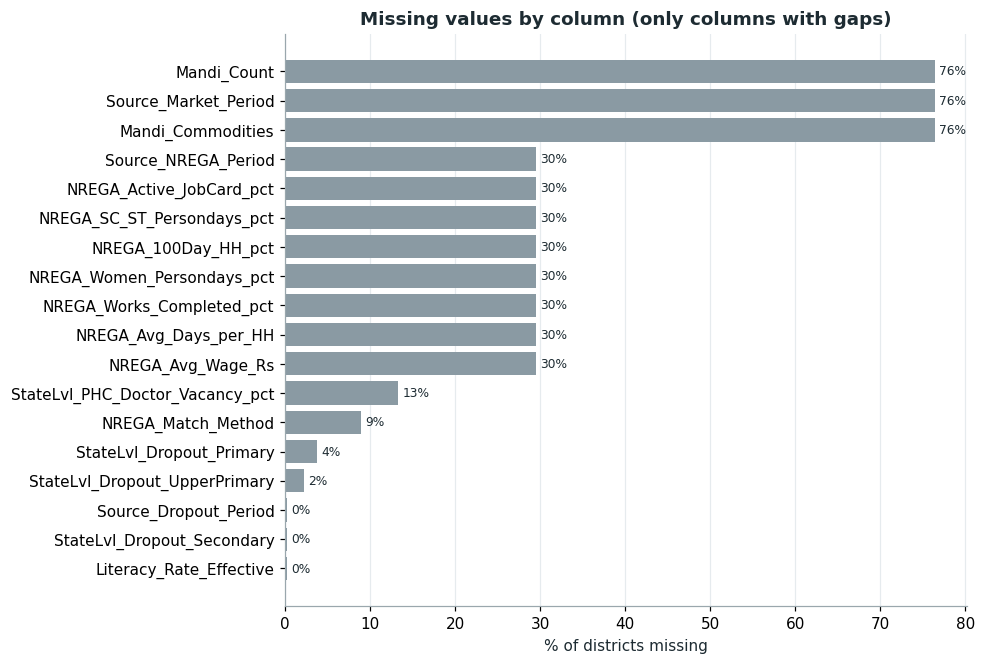

In [2]:
miss = df.isna().mean().mul(100)
miss = miss[miss > 0].sort_values()
fig, ax = plt.subplots(figsize=(8, .32 * len(miss) + 1))
ax.barh(miss.index, miss.values, color=PAL["muted"])
for i, v in enumerate(miss.values):
    ax.text(v + .5, i, f"{v:.0f}%", va="center", fontsize=8)
ax.set_xlabel("% of districts missing"); ax.set_title("Missing values by column (only columns with gaps)"); ax.grid(axis="y", visible=False)
save(fig, "eda_missingness"); plt.show()

* **Mandi_*** (~76 %): the mandi file is a one-day snapshot of 16 states - absence means *not observed*, never "no market".
* **NREGA_*** (~30 %): present-day districts; 2011 districts without a name match stay empty.
* **Literacy_Rate_Effective**: a single district (Bangalore Rural) is absent from the reference file.
* Everything else (Census, geography, railway, state-level context) is complete.

## 2 · Distributions of the core indicators

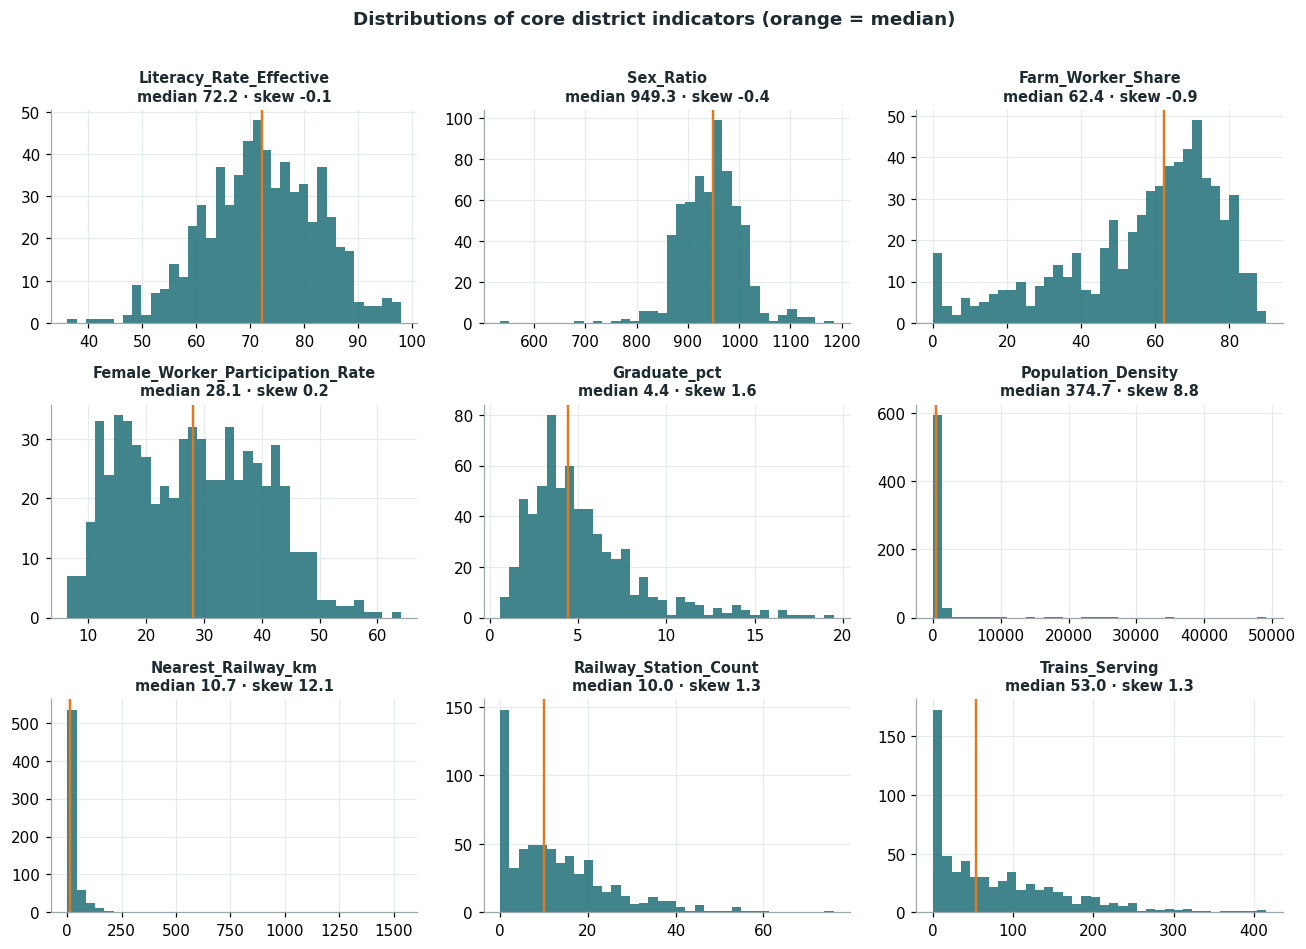

In [3]:
core = ["Literacy_Rate_Effective", "Sex_Ratio", "Farm_Worker_Share", "Female_Worker_Participation_Rate",
        "Graduate_pct", "Population_Density", "Nearest_Railway_km", "Railway_Station_Count", "Trains_Serving"]
fig, axes = plt.subplots(3, 3, figsize=(12, 8.5))
for ax, c in zip(axes.ravel(), core):
    x = df[c].dropna()
    ax.hist(x, bins=36, color=PAL["primary"], alpha=.85)
    ax.axvline(x.median(), color=PAL["accent"], lw=1.6)
    ax.set_title(f"{c}\nmedian {x.median():.1f} · skew {stats.skew(x):.1f}", fontsize=9.5)
fig.suptitle("Distributions of core district indicators (orange = median)", fontweight="bold", y=1.01)
fig.tight_layout(); save(fig, "eda_distributions"); plt.show()

Population density, railway distance and the station/train counts are **heavily right-skewed** (a few metros and remote islands),
so the index in notebook 04 uses log transforms and winsorised scaling rather than raw min-max.

In [4]:
desc = df[core].describe(percentiles=[.05, .25, .5, .75, .95]).T.round(2)
desc["skew"] = [stats.skew(df[c].dropna()) for c in core]
desc

,count,mean,std,min,5%,25%,50%,75%,95%,max,skew
Literacy_Rate_Effective,639.0,72.30,10.49,36.10,55.02,65.08,72.17,79.97,88.58,97.91,-0.146950
Sex_Ratio,640.0,945.44,60.60,533.57,862.96,906.29,949.26,982.65,1030.95,1184.40,-0.368646
Farm_Worker_Share,640.0,56.75,21.11,0.00,12.02,45.84,62.44,71.98,82.16,89.99,-0.943919
Female_Worker_Participation_Rate,640.0,28.33,11.76,6.36,11.39,18.14,28.06,37.81,47.20,64.04,0.205874
Graduate_pct,640.0,5.15,3.08,0.58,1.69,3.09,4.43,6.37,11.53,19.49,1.567160
Population_Density,640.0,980.40,3572.36,0.84,43.29,205.75,374.71,715.21,1593.14,49197.96,8.838568
Nearest_Railway_km,640.0,30.04,92.12,0.40,1.80,4.90,10.70,27.75,100.56,1532.60,12.100891
Railway_Station_Count,640.0,12.88,12.16,0.00,0.00,3.75,10.00,19.00,36.05,76.00,1.300911
Trains_Serving,640.0,78.45,81.54,0.00,0.00,8.00,53.00,125.00,237.10,416.00,1.270351


## 3 · Outliers (IQR rule)

In [5]:
def iqr_out(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum()
out = pd.Series({c: iqr_out(df[c].dropna()) for c in core}, name="IQR outliers").to_frame()
out["%"] = (out.iloc[:, 0] / len(df) * 100).round(1)
print(out)
print("\nLargest Nearest_Railway_km (islands / remote):")
print(df.nlargest(6, "Nearest_Railway_km")[["State_name", "District_name", "Nearest_Railway_km"]].to_string(index=False))
print("\nDensest districts:")
print(df.nlargest(5, "Population_Density")[["State_name", "District_name", "Population_Density"]].round(0).to_string(index=False))

                                  IQR outliers     %
Literacy_Rate_Effective                      3   0.5
Sex_Ratio                                   19   3.0
Farm_Worker_Share                           23   3.6
Female_Worker_Participation_Rate             0   0.0
Graduate_pct                                33   5.2
Population_Density                          40   6.2
Nearest_Railway_km                          68  10.6
Railway_Station_Count                       21   3.3
Trains_Serving                              13   2.0

Largest Nearest_Railway_km (islands / remote):
                 State_name             District_name  Nearest_Railway_km
ANDAMAN AND NICOBAR ISLANDS                  Nicobars              1532.6
ANDAMAN AND NICOBAR ISLANDS             South Andaman              1168.6
ANDAMAN AND NICOBAR ISLANDS North  AND Middle Andaman              1061.7
                LAKSHADWEEP               Lakshadweep               316.9
          JAMMU AND KASHMIR               Leh(Ladakh

These outliers are **real** (Lakshadweep/Andaman are >1,000 km from the mainland network; Delhi and Mumbai are extremely dense),
so they are kept and handled by transformation, not deleted.

## 4 · Which indicators move together? (Spearman)

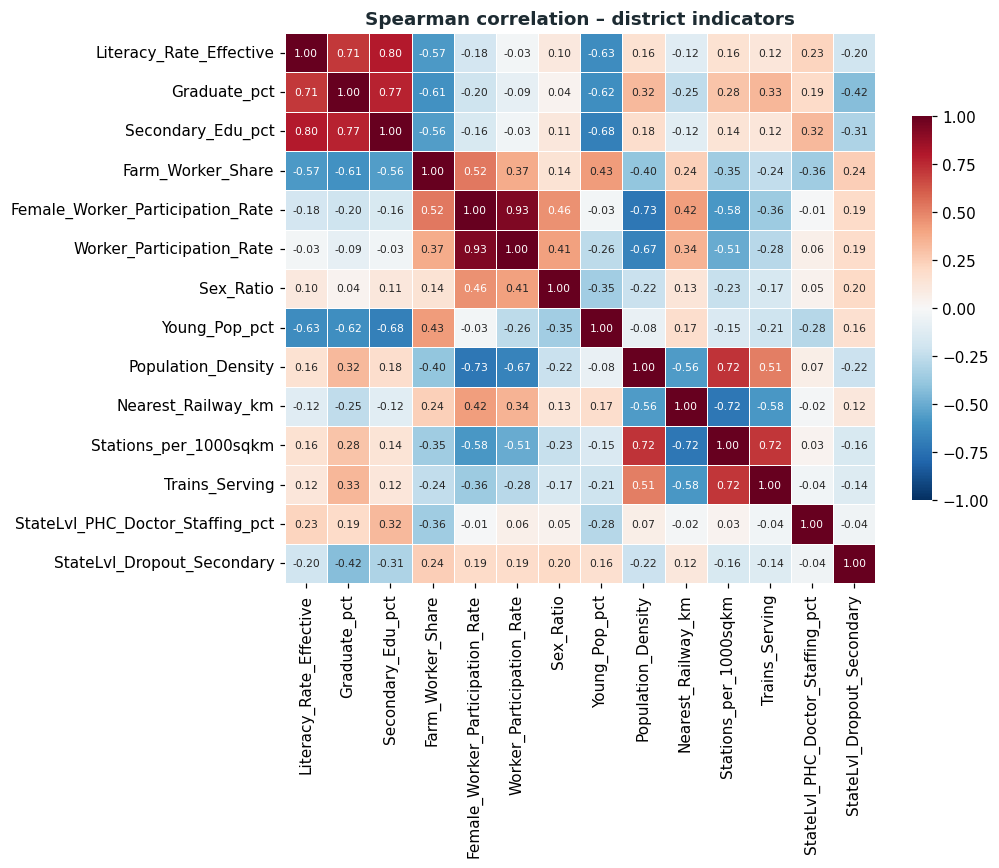

In [6]:
cols = ["Literacy_Rate_Effective", "Graduate_pct", "Secondary_Edu_pct", "Farm_Worker_Share", "Female_Worker_Participation_Rate",
        "Worker_Participation_Rate", "Sex_Ratio", "Young_Pop_pct", "Population_Density", "Nearest_Railway_km", "Stations_per_1000sqkm",
        "Trains_Serving", "StateLvl_PHC_Doctor_Staffing_pct", "StateLvl_Dropout_Secondary"]
cm = df[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(cm, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=.5,
            cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Spearman correlation – district indicators"); ax.grid(False)
fig.tight_layout(); save(fig, "eda_correlation"); plt.show()

In [7]:
pairs = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack().rename("rho").reset_index()
pairs["abs"] = pairs.rho.abs()
pairs.sort_values("abs", ascending=False).head(10).drop(columns="abs").round(2)

,level_0,level_1,rho
61,Female_Worker_Participation_Rate,Worker_Participation_Rate,0.93
2,Literacy_Rate_Effective,Secondary_Edu_pct,0.80
16,Graduate_pct,Secondary_Edu_pct,0.77
64,Female_Worker_Participation_Rate,Population_Density,-0.73
122,Population_Density,Stations_per_1000sqkm,0.72
136,Nearest_Railway_km,Stations_per_1000sqkm,-0.72
151,Stations_per_1000sqkm,Trains_Serving,0.72
1,Literacy_Rate_Effective,Graduate_pct,0.71
35,Secondary_Edu_pct,Young_Pop_pct,-0.68
78,Worker_Participation_Rate,Population_Density,-0.67


## 5 · Rurality vs outcomes
`Farm_Worker_Share` (cultivators + agricultural labourers as a share of all workers) is the rurality proxy,
because the supplied Census file has no urban/rural split.

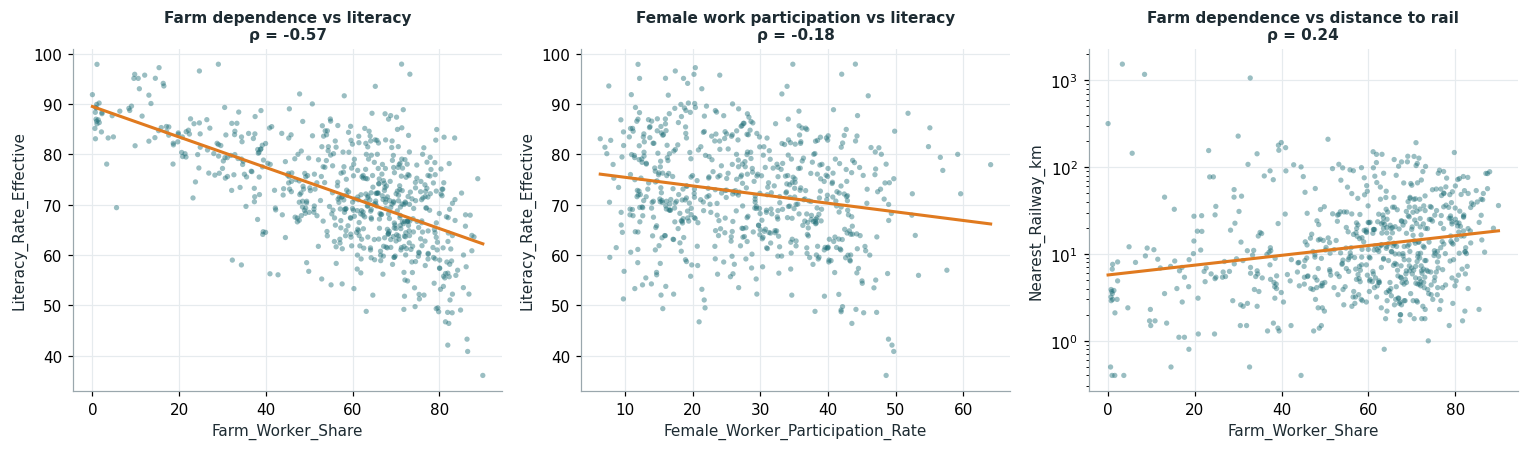

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (x, y, t) in zip(axes, [("Farm_Worker_Share", "Literacy_Rate_Effective", "Farm dependence vs literacy"),
                                ("Female_Worker_Participation_Rate", "Literacy_Rate_Effective", "Female work participation vs literacy"),
                                ("Farm_Worker_Share", "Nearest_Railway_km", "Farm dependence vs distance to rail")]):
    d = df[[x, y]].dropna()
    ax.scatter(d[x], d[y], s=12, alpha=.45, color=PAL["primary"], edgecolor="none")
    if y == "Nearest_Railway_km":
        ax.set_yscale("log")
    z = np.polyfit(d[x], np.log10(d[y]) if y == "Nearest_Railway_km" else d[y], 1)
    xs = np.linspace(d[x].min(), d[x].max(), 50)
    ax.plot(xs, 10 ** np.polyval(z, xs) if y == "Nearest_Railway_km" else np.polyval(z, xs), color=PAL["accent"], lw=2)
    rho, p = stats.spearmanr(d[x], d[y])
    ax.set_title(f"{t}\nρ = {rho:.2f}", fontsize=10); ax.set_xlabel(x); ax.set_ylabel(y)
fig.tight_layout(); save(fig, "eda_rurality_scatter"); plt.show()

## 6 · State view – where are the gaps?

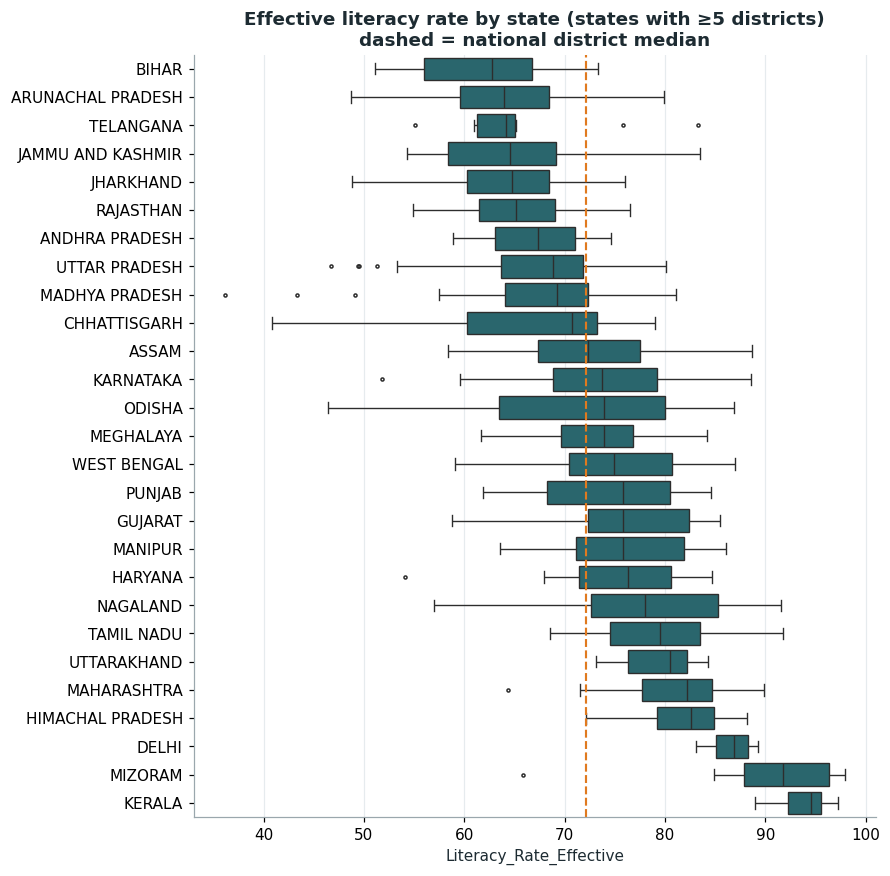

,districts,population_m,literacy_eff_median,farm_share_median,nearest_rail_km_median,pct_districts_no_station,female_wpr_median
State_Current,,,,,,,
BIHAR,38.0,104.1,62.8,74.1,5.6,5.3,17.7
ARUNACHAL PRADESH,16.0,1.4,64.0,61.3,97.3,100.0,37.1
TELANGANA,10.0,35.2,64.2,64.1,14.5,0.0,42.8
JAMMU AND KASHMIR,22.0,12.5,64.6,45.0,99.2,77.3,19.3
JHARKHAND,24.0,33.0,64.7,71.4,13.4,8.3,30.9
RAJASTHAN,33.0,68.5,65.1,65.3,11.3,3.0,36.9
ANDHRA PRADESH,13.0,49.4,67.3,63.5,7.5,0.0,35.1
UTTAR PRADESH,71.0,199.8,68.9,66.8,5.9,1.4,16.7


In [9]:
st = (df.groupby("State_Current").apply(lambda g: pd.Series({
    "districts": len(g), "population_m": g.Population.sum() / 1e6,
    "literacy_eff_median": g.Literacy_Rate_Effective.median(), "farm_share_median": g.Farm_Worker_Share.median(),
    "nearest_rail_km_median": g.Nearest_Railway_km.median(), "pct_districts_no_station": (g.Railway_Station_Count == 0).mean() * 100,
    "female_wpr_median": g.Female_Worker_Participation_Rate.median()})).round(1)).sort_values("literacy_eff_median")
st.to_csv(PROCESSED / "state_summary.csv")
order = df.groupby("State_Current").Literacy_Rate_Effective.median().sort_values().index
big = df.State_Current.value_counts()[lambda s: s >= 5].index
fig, ax = plt.subplots(figsize=(8, 9))
sns.boxplot(data=df[df.State_Current.isin(big)], y="State_Current", x="Literacy_Rate_Effective", order=[o for o in order if o in big],
            color=PAL["primary"], fliersize=2, linewidth=.9, ax=ax)
ax.axvline(df.Literacy_Rate_Effective.median(), color=PAL["accent"], ls="--", lw=1.4)
ax.set_title("Effective literacy rate by state (states with ≥5 districts)\ndashed = national district median"); ax.set_ylabel("")
save(fig, "eda_state_literacy"); plt.show()
st.head(8)

### Is the state a bigger driver than local factors?
Share of variance in each indicator that sits *between* states (η² from one-way ANOVA):

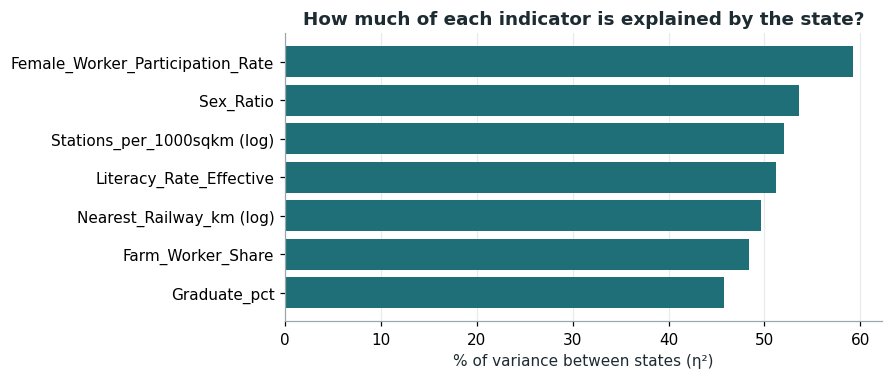

Graduate_pct                        45.8
Farm_Worker_Share                   48.4
Nearest_Railway_km (log)            49.7
Literacy_Rate_Effective             51.2
Stations_per_1000sqkm (log)         52.1
Sex_Ratio                           53.6
Female_Worker_Participation_Rate    59.3
dtype: float64

In [10]:
def eta2(col, log=False):
    d = df[["State_Current", col]].dropna()
    if log:
        d[col] = np.log1p(d[col])
    grand = d[col].mean()
    ssb = d.groupby("State_Current")[col].apply(lambda s: len(s) * (s.mean() - grand) ** 2).sum()
    return ssb / ((d[col] - grand) ** 2).sum()
e = pd.Series({**{c: eta2(c) for c in ["Literacy_Rate_Effective", "Farm_Worker_Share", "Female_Worker_Participation_Rate", "Sex_Ratio", "Graduate_pct"]},
               **{c + " (log)": eta2(c, log=True) for c in ["Nearest_Railway_km", "Stations_per_1000sqkm"]}}).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(e.index, e.values * 100, color=PAL["primary"]); ax.set_xlabel("% of variance between states (η²)")
ax.set_title("How much of each indicator is explained by the state?"); ax.grid(axis="y", visible=False)
save(fig, "eda_state_variance"); plt.show()
(e * 100).round(1)

For every indicator **roughly half (46-59 %) of the variance lies between states and half within them**.
A state average therefore hides as much variation as it reveals – district-level measurement is justified for
social *and* physical-access indicators. (Raw `Nearest_Railway_km` would be dominated by the island groups, so the log is used.)

## 7 · Rail access across India

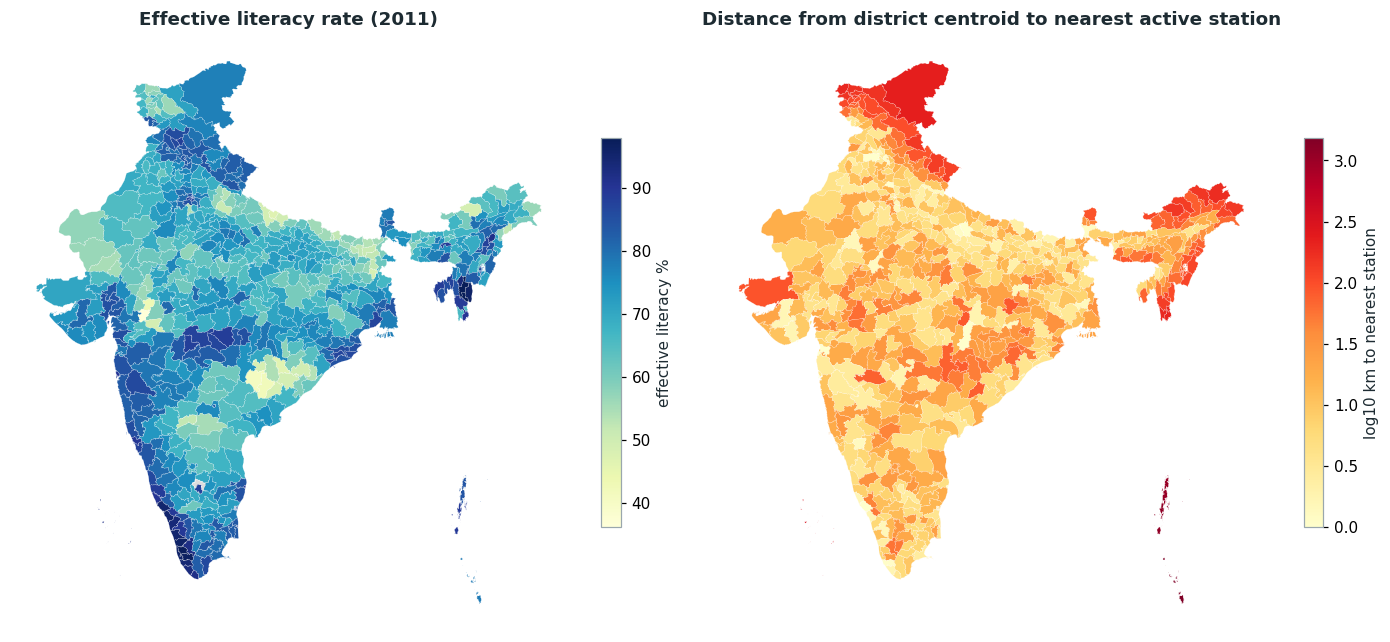

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
geo.plot(column="Literacy_Rate_Effective", cmap="YlGnBu", linewidth=.1, edgecolor="white", legend=True,
         legend_kwds={"shrink": .6, "label": "effective literacy %"}, ax=axes[0], missing_kwds={"color": "#dddddd"})
axes[0].set_title("Effective literacy rate (2011)")
geo.assign(d=np.log10(geo.Nearest_Railway_km.clip(lower=1))).plot(column="d", cmap="YlOrRd", linewidth=.1, edgecolor="white", legend=True,
         legend_kwds={"shrink": .6, "label": "log10 km to nearest station"}, ax=axes[1])
axes[1].set_title("Distance from district centroid to nearest active station")
for a in axes: a.set_axis_off(); a.grid(False)
fig.tight_layout(); save(fig, "eda_maps_literacy_rail"); plt.show()

In [12]:
far = (df.Nearest_Railway_km > 50)
print(f"Districts whose centroid is >50 km from any active station: {far.sum()} ({far.mean() * 100:.1f}%), home to {df.loc[far, 'Population'].sum() / 1e6:.1f} M people (2011)")
print(f"Districts with no timetabled station inside: {(df.Railway_Station_Count == 0).sum()} ({(df.Railway_Station_Count == 0).mean() * 100:.1f}%)")

Districts whose centroid is >50 km from any active station: 87 (13.6%), home to 42.3 M people (2011)
Districts with no timetabled station inside: 126 (19.7%)


## 8 · Hypothesis tests
Non-parametric tests are used because the indicators are skewed.

**H1.** Districts with at least one timetabled railway station have higher literacy than those without.
**H2.** Literacy is related to female worker participation (two-sided Spearman, bootstrap CI).
**H3.** Literacy differs across *regions* (Kruskal–Wallis by state).

In [13]:
has = df.Railway_Station_Count > 0
a, b = df.loc[has, "Literacy_Rate_Effective"].dropna(), df.loc[~has, "Literacy_Rate_Effective"].dropna()
u = stats.mannwhitneyu(a, b, alternative="greater")
cles = u.statistic / (len(a) * len(b))
print(f"H1  median literacy {a.median():.1f} (station) vs {b.median():.1f} (no station) | Mann-Whitney p={u.pvalue:.2g} | P(station > none)={cles:.2f}")
d = df[["Female_Worker_Participation_Rate", "Literacy_Rate_Effective"]].dropna()
rho, p = stats.spearmanr(*d.values.T)
boot = [stats.spearmanr(*d.sample(len(d), replace=True, random_state=i).values.T)[0] for i in range(500)]
print(f"H2  Spearman rho = {rho:.2f} (95% bootstrap CI {np.percentile(boot, 2.5):.2f}..{np.percentile(boot, 97.5):.2f}), p={p:.2g}")
groups = [g.Literacy_Rate_Effective.dropna().values for _, g in df.groupby("State_Current") if len(g) >= 5]
kw = stats.kruskal(*groups)
print(f"H3  Kruskal-Wallis H={kw.statistic:.1f}, p={kw.pvalue:.2g} over {len(groups)} states")

H1  median literacy 72.0 (station) vs 72.4 (no station) | Mann-Whitney p=0.41 | P(station > none)=0.51


H2  Spearman rho = -0.18 (95% bootstrap CI -0.26..-0.10), p=3e-06
H3  Kruskal-Wallis H=300.4, p=1.7e-48 over 27 states


**Reading.**
* **H1 is rejected** (p ≈ 0.4, effect ≈ 0.5 = coin-flip): having a timetabled station inside the district is *not* associated with literacy.
  Rail access and social development are largely independent dimensions – a key reason an *index* needs several pillars rather than one proxy.
* **H2** has a negative sign: women's *recorded* work participation is highest in poor, farm-dependent districts (farm labour out of necessity),
  so female participation is **not** used as a positive access indicator in notebook 04.
* **H3**: literacy differs strongly between states (p ≈ 1e-48).

## 9 · NREGA and market coverage (supporting data)

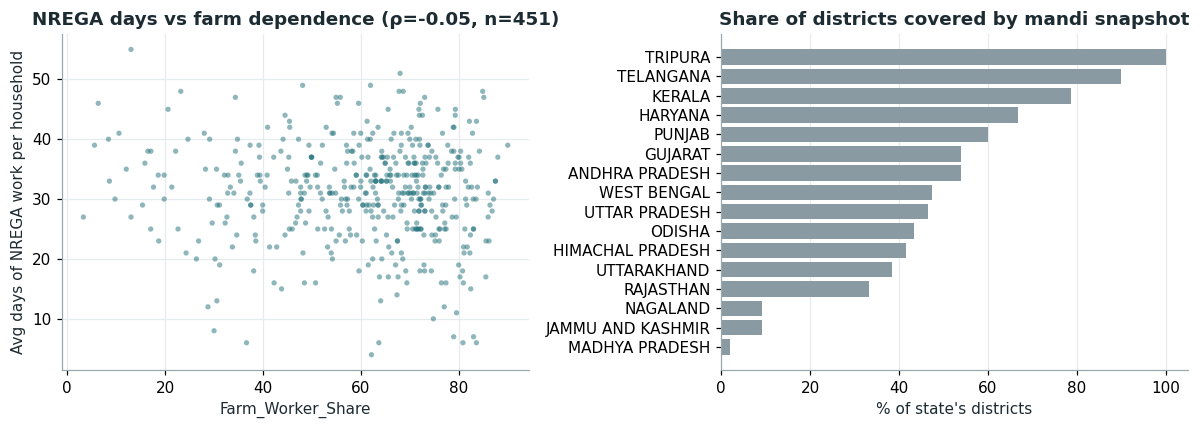

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
d = df[["Farm_Worker_Share", "NREGA_Avg_Days_per_HH"]].dropna()
axes[0].scatter(d.Farm_Worker_Share, d.NREGA_Avg_Days_per_HH, s=12, alpha=.5, color=PAL["primary"], edgecolor="none")
axes[0].set_xlabel("Farm_Worker_Share"); axes[0].set_ylabel("Avg days of NREGA work per household")
axes[0].set_title(f"NREGA days vs farm dependence (ρ={stats.spearmanr(d.iloc[:,0], d.iloc[:,1])[0]:.2f}, n={len(d)})")
mc = df.groupby("State_Current").Mandi_Count.apply(lambda s: s.notna().mean() * 100).sort_values()
mc = mc[mc > 0]
axes[1].barh(mc.index, mc.values, color=PAL["muted"]); axes[1].set_title("Share of districts covered by mandi snapshot")
axes[1].set_xlabel("% of state's districts"); axes[1].grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "eda_nrega_mandi"); plt.show()

## 10 · Take-aways that shape the modelling
1. The **Census gives the social base**; **railways give the only district-level physical-access measure** (nearly independent of literacy); health is only state-level.
2. Skew → log transforms + winsorised scaling.
3. About half of the variance in every indicator is **within** states → district-level scoring is justified.
4. NREGA and mandi coverage are partial → supporting evidence, not index components.